[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_08/MFM_ch8_esr_case/MFM_ch8_esr_case.ipynb)

# MFM_ch8_esr_case

Case study, Bayer and Dimitriadis (2022), Expected Shortfall Regression (ESR) backtesting: Table 3 of the paper (share of the 200 largest S&P 500 stocks for which the one-sided Intercept ESR test rejects the Expected Shortfall (ES) 2.5% forecasts at 5%) and its replication on 11 large S&P 500 stocks, January 2010 - August 2019: Generalised Autoregressive Conditional Heteroskedasticity (GARCH)(1,1) with Normal or Student-t innovations, rolling windows of 250-2000 days, refits every 5-250 days, one-sided Intercept ESR test with the esback package of the authors. Every attempted fit is reported. Singular fits are listed and excluded only from the valid-fit denominator; they are not non-rejections. If any fit fails, this run is a diagnostic and does not fully reproduce the stored course snapshot. No pseudoinverse is substituted. Stored benchmarks were reproduced with Python 3.13.9, NumPy 2.3.5, SciPy 1.16.3, pandas 2.3.3, statsmodels 0.14.5 and arch 8.0.0; R 4.6.1, esback 0.3.1 and esreg 0.6.2. Numerical optimisation is version-sensitive: see [requirements.txt](./requirements.txt) before attempting exact replication.

*Modelling Financial Markets (MFM), Chapter 8: Backtesting and Evaluating Risk Forecasts. Author: Daniel Traian Pele.*

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_8'
    os.makedirs(OUT_DIR, exist_ok=True)
    os.chdir(OUT_DIR)  # relative chart and CSV outputs persist in Drive
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261016T144910-f49bf4


In [ ]:
import os
import sys
import subprocess
try:
    import arch  # GARCH estimation
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'], check=True)
import pickle
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats, optimize
from numpy.lib.stride_tricks import sliding_window_view
import warnings
warnings.filterwarnings('ignore')

## Data and backtesting tools

Daily closes from the course data, loaded automatically; EUR/RON: BNR (National Bank of Romania) reference rate. Rolling one-day-ahead Value-at-Risk (VaR)/ES forecasts (1000-day window) and all backtests.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
# use the local copy of the course data when running inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')

# name -> (symbol, start date); indices/crypto: closing price
SOURCES = {
    'sp500':  ('GSPC.INDX', '1990-01-01'),
    'bet':    ('BET', '1997-09-19'),
    'btc':    ('BTC-USD.CC', '2014-09-17'),
    'eurron': ('REF:EUR', '2005-07-01'),        # BNR reference rate, since the introduction of the new leu
}
LABELS = {'sp500': 'S&P 500', 'bet': 'BET', 'btc': 'Bitcoin', 'eurron': 'EUR/RON'}
ASSETS = list(SOURCES)

_CACHE = {}


def read_market(symbol):
    """Read data/market/<SYMBOL>.csv locally or from the GitHub repository."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end='2026-09-18'):
    """Official RON reference rate published by the BNR (yearly XML archives)."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    import re
    import urllib.request
    rows = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}">([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_price(name):
    """Price series (close) of the asset."""
    symbol, start = SOURCES[name]
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start)
    p = read_market(symbol)['close'].loc[start:]
    return p[p > 0].dropna()


def load_returns(name):
    """Daily log returns on the series' own calendar."""
    return np.log(load_price(name)).diff().dropna()


# =============================================================================
# VaR / ES FORECASTS ON A ROLLING WINDOW (one day ahead)
# =============================================================================
W = 1000                       # estimation window (observations)
REFIT = 20                     # GARCH / t / EVT parameters are re-estimated every 20 days
LEVELS = (0.01, 0.025, 0.05)   # tail probabilities: VaR 1%, VaR 2.5%, VaR 5%
A_ES = 0.025                   # ES 2.5% (FRTB)
K_TAIL = int(np.ceil(A_ES * W))   # number of tail order statistics (Z2 simulation)
MODELS = ['HS', 'Normal', 'Student-t', 'GARCH-t', 'FHS', 'GARCH-EVT']
EVAL_FROM = '2007-01-01'       # first possible evaluation day
EVT_Q = 0.90                   # POT threshold: 90% quantile of the standardised losses


def t_std_q(nu, a):
    """Quantile of order 1-a of the standardised Student-t distribution (unit variance)."""
    return stats.t.ppf(1 - a, nu) * np.sqrt((nu - 2) / nu)


def t_std_es(nu, a):
    """ES at level 1-a of the standardised Student-t distribution (unit variance)."""
    q = stats.t.ppf(1 - a, nu)
    return stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1) * np.sqrt((nu - 2) / nu)


def garch_fit(x, prev=None):
    """Same Student-t GARCH(1,1); unresolved boundary fits cannot update parameters.

    The numerical band diagnoses precision near alpha+beta=1. It neither clamps
    parameters nor changes the maintained finite-variance restriction alpha+beta<1.
    Only a previously clearly admissible fit may be reused, with status reported.
    """
    from arch import arch_model
    resolution = 1e-8
    c = 1 / x.std()
    res = arch_model(c * x, mean='Constant', vol='GARCH', p=1, q=1, dist='t',
                     rescale=False).fit(disp='off', show_warning=False)
    mu, om, a, b, nu = res.params.values
    finite = np.isfinite([mu, om, a, b, nu, res.loglikelihood]).all()
    gap = 1-a-b
    if res.convergence_flag != 0 or not finite or abs(mu)>=1 or om<=0 or a<0 or b<0 or nu<=2:
        status = 'fit-invalid'
    elif abs(gap) <= resolution:
        status = 'numeric-unidentified'
    elif gap < 0:
        status = 'finite-variance-inadmissible'
    else:
        status = 'clearly-admissible'
    garch_fit.last_diagnostic = {
        'status':status, 'flag':int(res.convergence_flag),
        'raw_persistence':float(a+b) if np.isfinite(a+b) else None,
        'loglikelihood':float(res.loglikelihood) if np.isfinite(res.loglikelihood) else None,
        'resolution':resolution,
        'candidate_params_scaled':[float(v) if np.isfinite(v) else None for v in (mu,om,a,b,nu)],
        'fallback':status!='clearly-admissible'}
    if status=='clearly-admissible':
        return mu/c, om/c**2, a, b, nu
    if prev is None:
        raise RuntimeError(f'GARCH fit is {status}; no earlier clearly admissible parameters are available')
    pm, po, pa, pb, pn = prev
    if not (np.isfinite(prev).all() and po>0 and pa>=0 and pb>=0 and 1-pa-pb>resolution and pn>2):
        raise RuntimeError('Previous GARCH parameters are not clearly admissible; cannot use fallback')
    return prev


def garch_filter(x, mu, om, a, b, s2_0):
    """Conditional variance: s2[t] uses only x[:t]; the last element is the forecast."""
    e2 = (x - mu) ** 2
    s2 = np.empty(len(x) + 1)
    s2[0] = s2_0
    for t in range(len(x)):
        s2[t + 1] = om + a * e2[t] + b * s2[t]
    return s2


def gpd_tail(y, a_list, q=EVT_Q):
    """EVT (POT): GPD on the excesses of standardised losses over the q quantile; VaR/ES at levels 1-a."""
    u = np.quantile(y, q)
    exc = y[y > u] - u
    xi, _, beta = stats.genpareto.fit(exc, floc=0)
    pu = len(exc) / len(y)
    var = {a: u + beta / xi * ((a / pu) ** (-xi) - 1) for a in a_list}
    es = {a: (var[a] + beta - xi * u) / (1 - xi) for a in a_list}
    return dict(u=u, xi=xi, beta=beta, pu=pu, var=var, es=es)


def gpd_cdf(y, g, emp):
    """EVT distribution function: empirical below the threshold, GPD above it."""
    if y <= g['u']:
        return np.mean(emp <= y)
    base = 1 + g['xi'] * (y - g['u']) / g['beta']
    return 1.0 if base <= 0 else 1 - g['pu'] * base ** (-1 / g['xi'])


def rolling_forecasts(r, eval_from=EVAL_FROM, w=W, refit=REFIT):
    """One-day-ahead VaR (LEVELS) and ES (A_ES) forecasts for the loss L = -r, for all models.

    Result: dict model -> DataFrame (index = forecast day) with columns
    VaR1, VaR2.5, VaR5, ES2.5, ES1, pit (F(L_t)), scale, mu, plus information for tail simulation."""
    r = r.dropna()
    L = -r.values
    idx = r.index
    start = max(w, int(np.searchsorted(idx, pd.Timestamp(eval_from))))
    T = len(r) - start
    days = idx[start:]
    out = {m: {k: np.full(T, np.nan) for k in ['VaR1', 'VaR2.5', 'VaR5', 'ES2.5', 'ES1', 'pit', 'scale', 'mu', 'nu',
                                               'u', 'xi', 'beta', 'pu']} for m in MODELS}
    tails = {m: np.full((T, K_TAIL), np.nan) for m in ('HS', 'FHS')}
    lev = {0.01: 'VaR1', 0.025: 'VaR2.5', 0.05: 'VaR5'}
    Lcur = L[start:]

    # --- HS and Normal: vectorised over windows
    win = sliding_window_view(L[:-1], w)[start - w:]          # window for day t: L[t-w:t]
    srt = np.sort(win, axis=1)
    o = out['HS']
    for a, k in lev.items():
        o[k] = np.quantile(win, 1 - a, axis=1)
    for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
        v = np.quantile(win, 1 - a, axis=1)
        o[k] = np.nanmean(np.where(win >= v[:, None], win, np.nan), axis=1)
    o['pit'] = (np.sum(win < Lcur[:, None], axis=1) + 0.5 * np.sum(win == Lcur[:, None], axis=1)) / w
    o['scale'] = win.std(axis=1, ddof=1)
    o['mu'] = np.zeros(T)
    tails['HS'] = srt[:, -K_TAIL:]
    mu_w, sd_w = -win.mean(axis=1), win.std(axis=1, ddof=1)     # mean of returns, standard deviation
    o = out['Normal']
    for a, k in lev.items():
        o[k] = -mu_w + sd_w * stats.norm.ppf(1 - a)
    for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
        o[k] = -mu_w + sd_w * stats.norm.pdf(stats.norm.ppf(1 - a)) / a
    o['pit'] = stats.norm.cdf((Lcur + mu_w) / sd_w)
    o['scale'], o['mu'] = sd_w, mu_w

    # --- models re-estimated every `refit` days
    prev = None
    source_origin = None
    refit_records = []
    daily_status = np.empty(T, dtype=object)
    daily_age = np.empty(T, dtype=int)
    daily_source = np.empty(T, dtype=object)
    daily_estimation_end = np.empty(T, dtype=object)
    daily_fallback = np.empty(T, dtype=bool)
    for b0 in range(0, T, refit):
        t0 = start + b0
        b1 = min(T, b0 + refit)
        x = r.values[t0 - w:t0]
        # unconditional Student-t: degrees of freedom, location and scale by MLE
        nu_t, loc_t, sc_t = stats.t.fit(x)
        nu_t = max(nu_t, 2.2)
        sd_t = sc_t * np.sqrt(nu_t / (nu_t - 2))                # implied standard deviation
        # GARCH(1,1)-t
        prev = garch_fit(x, prev if b0 > 0 else None)
        fit_record = dict(garch_fit.last_diagnostic)
        if not fit_record['fallback']:
            source_origin = b0
        if source_origin is None:
            raise RuntimeError('No admissible source fit for rolling forecasts')
        fit_record.update(refit_date=str(days[b0].date()),
                          estimation_end_date=str(idx[t0-1].date()),
                          parameter_source_date=str(days[source_origin].date()),
                          parameter_estimation_end_date=str(idx[start+source_origin-1].date()),
                          age_at_refit_trading_rows=int(b0-source_origin))
        refit_records.append(fit_record)
        daily_status[b0:b1] = fit_record['status']
        daily_age[b0:b1] = np.arange(b0,b1)-source_origin
        daily_source[b0:b1] = str(days[source_origin].date())
        daily_fallback[b0:b1] = fit_record['fallback']
        daily_estimation_end[b0:b1] = str(idx[start+source_origin-1].date())
        mu, om, al, be, nu = prev
        nu = max(nu, 2.2)
        xx = r.values[t0 - w:t0 + (b1 - b0)]
        s2 = garch_filter(xx, mu, om, al, be, np.var(x[:50]))
        z = (x - mu) / np.sqrt(s2[:w])
        y = np.sort(-z)                                         # standardised losses
        g = gpd_tail(y, (0.01, 0.025, 0.05))
        for t in range(b0, b1):
            j = w + (t - b0)
            sig = np.sqrt(s2[j])
            Lt = Lcur[t]
            # unconditional Student-t
            o = out['Student-t']
            for a, k in lev.items():
                o[k][t] = -loc_t + sd_t * t_std_q(nu_t, a)
            o['ES2.5'][t] = -loc_t + sd_t * t_std_es(nu_t, 0.025)
            o['ES1'][t] = -loc_t + sd_t * t_std_es(nu_t, 0.01)
            o['pit'][t] = stats.t.cdf((Lt + loc_t) / sc_t, nu_t)
            o['scale'][t], o['mu'][t], o['nu'][t] = sd_t, loc_t, nu_t
            # GARCH-t
            o = out['GARCH-t']
            for a, k in lev.items():
                o[k][t] = -mu + sig * t_std_q(nu, a)
            o['ES2.5'][t] = -mu + sig * t_std_es(nu, 0.025)
            o['ES1'][t] = -mu + sig * t_std_es(nu, 0.01)
            o['pit'][t] = stats.t.cdf((Lt + mu) / sig / np.sqrt((nu - 2) / nu), nu)
            o['scale'][t], o['mu'][t], o['nu'][t] = sig, mu, nu
            # FHS: empirical quantiles of the standardised losses
            o = out['FHS']
            for a, k in lev.items():
                o[k][t] = -mu + sig * np.quantile(y, 1 - a)
            for a, k in ((0.025, 'ES2.5'), (0.01, 'ES1')):
                q = np.quantile(y, 1 - a)
                o[k][t] = -mu + sig * y[y >= q].mean()
            o['pit'][t] = np.mean(y < (Lt + mu) / sig)
            o['scale'][t], o['mu'][t] = sig, mu
            tails['FHS'][t] = -mu + sig * y[-K_TAIL:]
            # GARCH-EVT
            o = out['GARCH-EVT']
            for a, k in lev.items():
                o[k][t] = -mu + sig * g['var'][a]
            o['ES2.5'][t] = -mu + sig * g['es'][0.025]
            o['ES1'][t] = -mu + sig * g['es'][0.01]
            o['pit'][t] = gpd_cdf((Lt + mu) / sig, g, y)
            o['scale'][t], o['mu'][t] = sig, mu
            o['u'][t], o['xi'][t], o['beta'][t], o['pu'][t] = g['u'], g['xi'], g['beta'], g['pu']
    res = {}
    for m in MODELS:
        df = pd.DataFrame(out[m], index=days)
        df['L'] = Lcur
        res[m] = df
    # Metadata do not enter any forecast, loss, statistic, or common-sample selection.
    daily = pd.DataFrame({'fit_status':daily_status, 'fallback':daily_fallback,
                          'parameter_age_trading_rows':daily_age,
                          'parameter_source_date':daily_source,'parameter_estimation_end_date':daily_estimation_end}, index=days)
    counts = {s:sum(row['status']==s for row in refit_records) for s in
              ['clearly-admissible','numeric-unidentified','finite-variance-inadmissible','fit-invalid']}
    summary = {'policy':'finite-variance-resolution-1e-8-v1', 'refits_by_status':counts,
               'fallback_forecast_days':int(daily_fallback.sum()),
               'max_parameter_age_trading_rows':int(daily_age.max()) if T else 0,
               'age_definition':'trading rows since source refit origin; variance/residuals filtered on current data',
               'no_previous_fit':'raise error; never silently drop forecast rows'}
    for model in ['GARCH-t','FHS','GARCH-EVT']:
        res[model].attrs['garch_numerics'] = summary
    rolling_forecasts.last_diagnostics = {'summary':summary,'refits':refit_records,'daily':dict(forecast_date=[str(d.date()) for d in days],**daily.to_dict(orient='list'))}
    print('GARCH numerical status:', summary)
    if daily_fallback.any():
        print('Fallback parameters are stale; filtering still uses current observations.')
        spells = daily.loc[daily.fallback].groupby('parameter_source_date',sort=True).agg(
            fallback_days=('fallback','size'), max_age=('parameter_age_trading_rows','max'))
        print(spells.to_string())
    return res, tails


def get_forecasts(name):
    """Forecast cache tied to exact input, configuration, code and package versions."""
    import hashlib, json, types, sys
    from importlib.metadata import version
    r = load_returns(name)
    def code_record(code):
        def const(x):
            if isinstance(x, types.CodeType): return code_record(x)
            if isinstance(x, bytes): return {'bytes':x.hex()}
            if isinstance(x, tuple): return [const(v) for v in x]
            if isinstance(x, frozenset): return {'frozenset':sorted([const(v) for v in x],key=lambda v:json.dumps(v,sort_keys=True))}
            if x is None or isinstance(x,(str,int,float,bool)): return x
            return repr(x)
        return {'bytecode':code.co_code.hex(),'constants':[const(x) for x in code.co_consts],
                'names':code.co_names,'varnames':code.co_varnames,
                'argcount':code.co_argcount,'kwonlyargcount':code.co_kwonlyargcount}
    helpers = (garch_fit,garch_filter,rolling_forecasts,gpd_tail,gpd_cdf,t_std_q,t_std_es)
    config = {'policy':'finite-variance-resolution-1e-8-v1','name':name,
              'window':W,'refit':REFIT,'eval_from':EVAL_FROM,'tail_count':K_TAIL,'evt_q':EVT_Q,
              'models':MODELS,'python':sys.version,
              'versions':{p:version(p) for p in ['numpy','scipy','arch','pandas']},
              'code':{f.__name__:{'code':code_record(f.__code__),'defaults':f.__defaults__,'kwdefaults':f.__kwdefaults__} for f in helpers},
              'returns_sha256':hashlib.sha256(np.ascontiguousarray(r.values,dtype='<f8').tobytes()).hexdigest(),
              'dates_sha256':hashlib.sha256(np.ascontiguousarray(r.index.asi8,dtype='<i8').tobytes()).hexdigest()}
    fingerprint=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
    path=os.path.join(tempfile.gettempdir(),f'mfm_ch8_fc_v2_{fingerprint}.pkl')
    if os.path.exists(path):
        with open(path,'rb') as f: stored=pickle.load(f)
        if stored.get('fingerprint')==fingerprint:
            fc=stored['forecasts']
            report=stored.get('garch_numerics')
            if (report and report['summary']['policy']==config['policy'] and all(fc[0][m].attrs.get('garch_numerics',{}).get('policy')==config['policy'] for m in ['GARCH-t','FHS','GARCH-EVT'])):
                get_forecasts.last_cache_identity=fingerprint
                get_forecasts.last_diagnostics=report
                rolling_forecasts.last_diagnostics=report
                print('GARCH numerical status:',report['summary'])
                if report['summary']['fallback_forecast_days']:
                    print('Fallback parameters are stale; filtering still uses current observations.')
                    daily=pd.DataFrame(report['daily'])
                    print(daily.loc[daily.fallback].groupby('parameter_source_date').agg(
                        fallback_days=('fallback','size'),max_age=('parameter_age_trading_rows','max')).to_string())
                return fc
    fc=rolling_forecasts(r)
    report=rolling_forecasts.last_diagnostics
    get_forecasts.last_diagnostics=report
    stored={'fingerprint':fingerprint,'configuration':config,'forecasts':fc,'garch_numerics':report}
    temporary=None
    try:
        with tempfile.NamedTemporaryFile(mode='wb',dir=tempfile.gettempdir(),delete=False) as f:
            temporary=f.name
            pickle.dump(stored,f)
        os.replace(temporary,path)
    finally:
        if temporary and os.path.exists(temporary):os.unlink(temporary)
    get_forecasts.last_cache_identity=fingerprint
    return fc


# =============================================================================
# VaR TESTS
# =============================================================================
def kupiec(hits, p):
    """Kupiec POF test: LR_uc ~ chi2(1)."""
    hits = np.asarray(hits, int)
    T, x = len(hits), hits.sum()
    ph = x / T
    ll0 = (T - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (T - x) * np.log(1 - ph) + x * np.log(ph) if 0 < x < T else 0.0
    lr = -2 * (ll0 - ll1)
    return dict(T=T, x=int(x), rate=ph, LR=lr, p=stats.chi2.sf(lr, 1))


def transitions(hits):
    """Counts of the transitions n00, n01, n10, n11 of the hit sequence."""
    h = np.asarray(hits, int)
    a, b = h[:-1], h[1:]
    return dict(n00=int(np.sum((a == 0) & (b == 0))), n01=int(np.sum((a == 0) & (b == 1))),
                n10=int(np.sum((a == 1) & (b == 0))), n11=int(np.sum((a == 1) & (b == 1))))


def christoffersen_from_counts(n00, n01, n10, n11, p):
    """LR_ind (independence, first-order Markov chain) and LR_cc = LR_uc + LR_ind."""
    def xlogy(n, q):
        return n * np.log(q) if n > 0 else 0.0
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    l_ind = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    l_0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    lr_ind = -2 * (l_0 - l_ind)
    T, x = n00 + n01 + n10 + n11, n01 + n11
    lr_uc = -2 * (xlogy(T - x, 1 - p) + xlogy(x, p) - xlogy(T - x, 1 - pi) - xlogy(x, pi))
    lr_cc = lr_uc + lr_ind
    return dict(pi01=pi01, pi11=pi11, pi=pi, LR_ind=lr_ind, p_ind=stats.chi2.sf(lr_ind, 1),
                LR_uc=lr_uc, LR_cc=lr_cc, p_cc=stats.chi2.sf(lr_cc, 2))


def christoffersen(hits, p):
    return christoffersen_from_counts(**transitions(hits), p=p)


def durations(hits):
    """Durations (days) between breaches, with censoring flags for the first and last duration."""
    h = np.asarray(hits, int)
    pos = np.flatnonzero(h)
    if len(pos) == 0:
        return np.array([len(h)]), 1, 1
    D = np.diff(np.r_[-1, pos, len(h) - 1 if h[-1] == 0 else pos[-1]])
    D = D[D > 0]
    c1 = 1 if h[0] == 0 else 0
    cn = 1 if h[-1] == 0 else 0
    return D.astype(float), c1, cn


def duration_test(hits):
    """Christoffersen-Pelletier (2004) duration test: continuous Weibull approximation, H0: b = 1 (memoryless)."""
    D, c1, cn = durations(hits)
    if len(D) < 3:
        return dict(b=np.nan, LR=np.nan, p=np.nan, n=len(D))

    def nll(par, fix_b=False):
        a = np.exp(par[0])
        b = 1.0 if fix_b else np.exp(par[1])
        lf = np.log(b) + b * np.log(a) + (b - 1) * np.log(D) - (a * D) ** b
        ls = -(a * D) ** b
        ll = lf.copy()
        if c1:
            ll[0] = ls[0]
        if cn:
            ll[-1] = ls[-1]
        return -ll.sum()
    a0 = np.log(1 / D.mean())
    r1 = optimize.minimize(nll, [a0, 0.0], method='Nelder-Mead', options=dict(xatol=1e-8, fatol=1e-10, maxiter=4000))
    r0 = optimize.minimize(lambda p: nll(p, True), [a0], method='Nelder-Mead')
    lr = max(2 * (r0.fun - r1.fun), 0.0)
    return dict(b=float(np.exp(r1.x[1])), LR=lr, p=stats.chi2.sf(lr, 1), n=len(D))


def traffic_light(x, T=250, p=0.01):
    """Basel zone (green/yellow/red) for x exceptions in T days; cumulative Binomial probability."""
    cum = stats.binom.cdf(x, T, p)
    zone = 'green' if cum < 0.95 else ('yellow' if cum < 0.9999 else 'red')
    return zone, cum


# =============================================================================
# ES TESTS
# =============================================================================
def mcneil_frey(L, var, es, scale, B=5000, seed=0):
    """Exceedance residuals (L - ES)/sigma on days with L > VaR; H0: mean 0, H1: mean > 0 (i.i.d. bootstrap)."""
    hit = L > var
    e = ((L - es) / scale)[hit]
    n = len(e)
    if n < 3:
        return dict(n=n, mean=np.nan, t=np.nan, p=np.nan)
    tstat = e.mean() / (e.std(ddof=1) / np.sqrt(n))
    rng = np.random.default_rng(seed)
    ec = e - e.mean()
    bs = rng.choice(ec, (B, n), replace=True)
    tb = bs.mean(1) / (bs.std(1, ddof=1) / np.sqrt(n))
    return dict(n=n, mean=e.mean(), t=tstat, p=float(np.mean(tb >= tstat)))


def acerbi_szekely(L, var, es, a=A_ES):
    """Acerbi-Szekely (2014) Z1 and Z2 statistics, with losses positive."""
    hit = L > var
    T, n = len(L), hit.sum()
    z1 = 1 - np.mean(L[hit] / es[hit]) if n > 0 else np.nan
    z2 = 1 - np.sum(L[hit] / es[hit]) / (T * a)
    return z1, z2


def tail_sampler(df, model, tails, U):
    """Inverse loss distribution function for levels U > 1 - A_ES (matrix T x M)."""
    mu, sc = df['mu'].values[:, None], df['scale'].values[:, None]
    if model in ('HS', 'FHS'):
        k = np.clip(np.ceil((U - (1 - A_ES)) / A_ES * K_TAIL).astype(int) - 1, 0, K_TAIL - 1)
        return np.take_along_axis(tails[model], k, axis=1)
    if model == 'Normal':
        return -mu + sc * stats.norm.ppf(U)
    if model in ('Student-t', 'GARCH-t'):
        nu = df['nu'].values[:, None]
        return -mu + sc * stats.t.ppf(U, nu) * np.sqrt((nu - 2) / nu)
    if model == 'GARCH-EVT':
        u, xi, be, pu = (df[c].values[:, None] for c in ('u', 'xi', 'beta', 'pu'))
        return -mu + sc * (u + be / xi * (((1 - U) / pu) ** (-xi) - 1))
    raise ValueError(model)


def z_pvalues(df, model, tails, M=2000, seed=1, a=A_ES):
    """Simulated p-values under H0 (the model's forecast distribution) for Z1 and Z2."""
    L, var, es = df['L'].values, df['VaR2.5'].values, df['ES2.5'].values
    z1, z2 = acerbi_szekely(L, var, es, a)
    rng = np.random.default_rng(seed)
    T = len(L)
    z1s, z2s = np.empty(M), np.empty(M)
    step = 250
    for m0 in range(0, M, step):
        k = min(step, M - m0)
        U = rng.uniform(size=(T, k))
        hit = U > 1 - a
        Us = np.where(hit, U, 1 - a / 2)
        Ls = tail_sampler(df, model, tails, Us)
        ratio = np.where(hit, Ls / es[:, None], 0.0)
        z2s[m0:m0 + k] = 1 - ratio.sum(0) / (T * a)
        nh = hit.sum(0)
        z1s[m0:m0 + k] = 1 - ratio.sum(0) / np.maximum(nh, 1)
    return dict(Z1=z1, Z2=z2, p1=float(np.mean(z1s <= z1)), p2=float(np.mean(z2s <= z2)),
                crit2=float(np.quantile(z2s, 0.05)))


def du_escanciano(pit, a=A_ES, lags=5):
    """Du-Escanciano (2017): cumulative violation H_t = (1/a)(u_t - (1-a)) 1{u_t > 1-a};
    unconditional test U_ES ~ N(0,1) and conditional test C_ES (Box-Pierce, chi2(lags))."""
    u = np.clip(np.asarray(pit), 0, 1)
    H = (u - (1 - a)) / a * (u > 1 - a)
    T = len(H)
    U = np.sqrt(T) * (H.mean() - a / 2) / np.sqrt(a * (1 / 3 - a / 4))
    hc = H - a / 2
    g0 = np.mean(hc ** 2)
    rho = np.array([np.mean(hc[j:] * hc[:-j]) / g0 for j in range(1, lags + 1)])
    C = T * np.sum(rho ** 2)
    return dict(meanH=H.mean(), U=U, pU=2 * stats.norm.sf(abs(U)), C=C, pC=stats.chi2.sf(C, lags))


# =============================================================================
# FZ0 LOSS, DIEBOLD-MARIANO, MCS
# =============================================================================
def fz0(L, var, es, a=A_ES):
    """FZ0 loss (Patton, Ziegel & Chen, 2019), written for positive losses:
    FZ0 = (1/(a ES)) 1{L > VaR} (L - VaR) + VaR/ES + log(ES) - 1  (ES > 0)."""
    return (L > var) * (L - var) / (a * es) + var / es + np.log(es) - 1


def pinball(L, var, a):
    """Quantile (tick) loss: (1{L > VaR} - a)(L - VaR) >= 0, minimised in expectation by the 1-a quantile."""
    return ((L > var).astype(float) - a) * (L - var)


def nw_var(d, lags=None):
    """Long-run variance (Newey-West, Bartlett kernel)."""
    d = np.asarray(d) - np.mean(d)
    T = len(d)
    if lags is None:
        lags = int(np.floor(4 * (T / 100) ** (2 / 9)))
    v = np.mean(d ** 2)
    for j in range(1, lags + 1):
        v += 2 * (1 - j / (lags + 1)) * np.dot(d[j:], d[:-j]) / T     # autocovariance with divisor T (PSD)
    return v


def diebold_mariano(la, lb, lags=None):
    """DM = mean(d) / sqrt(LRV/T), d = la - lb; negative => A has the lower average loss."""
    d = np.asarray(la) - np.asarray(lb)
    dm = d.mean() / np.sqrt(nw_var(d, lags) / len(d))
    return dict(dbar=d.mean(), DM=dm, p=2 * stats.norm.sf(abs(dm)))


def mcs(losses, alpha=0.10, B=1000, block=10, seed=2):
    """Model confidence set (Hansen, Lunde & Nason, 2011), T_max statistic,
    circular block bootstrap. losses: DataFrame T x m. Result: MCS p-values."""
    rng = np.random.default_rng(seed)
    X = losses.values
    T, m = X.shape
    nb = int(np.ceil(T / block))
    idx = (rng.integers(0, T, (B, nb))[:, :, None] + np.arange(block)) % T
    idx = idx.reshape(B, -1)[:, :T]
    Lbar = X.mean(0)
    Lb = np.stack([X[i].mean(0) for i in idx])           # B x m
    alive = list(range(m))
    pvals, p_run = {}, 0.0
    while len(alive) > 1:
        a = np.array(alive)
        d = Lbar[a] - Lbar[a].mean()
        db = Lb[:, a] - Lb[:, a].mean(1, keepdims=True)
        se = np.sqrt(np.mean((db - d) ** 2, axis=0))
        t = d / se
        tb = ((db - d) / se).max(1)
        p = float(np.mean(tb >= t.max()))
        p_run = max(p_run, p)
        worst = a[np.argmax(t)]
        pvals[losses.columns[worst]] = p_run
        alive.remove(worst)
    pvals[losses.columns[alive[0]]] = 1.0
    return pd.Series(pvals)[losses.columns]


# =============================================================================
# CONFORMAL PREDICTION FOR VaR
# =============================================================================
def conformal_var(r, a=0.01, n_cal=250, n_sd=250, gamma=0.005, eval_from=EVAL_FROM):
    """Rolling split conformal VaR and ACI (Gibbs & Candes, 2021).

    Nonconformity score: s_t = L_t / sd_t, sd_t = standard deviation of the previous n_sd returns.
    VaR_t = sd_t * the order statistic k = ceil((n+1)(1-a)) of the last n_cal scores (+inf if k > n).
    ACI: a_{t+1} = a_t + gamma (a - err_t); if the required rank exceeds n, VaR = +inf.
    Rolling-standardised scores are only approximately exchangeable, even for i.i.d. returns."""
    r = r.dropna()
    L = -r.values
    sd = pd.Series(r.values).rolling(n_sd).std().shift(1).values   # only information up to t-1
    s = L / sd
    start = max(n_sd + n_cal + 1, int(np.searchsorted(r.index, pd.Timestamp(eval_from))))
    T = len(r) - start
    var_s, var_a, a_path = np.empty(T), np.empty(T), np.empty(T)
    at = a
    for i in range(T):
        t = start + i
        cal = np.sort(s[t - n_cal:t])
        k = int(np.ceil((n_cal + 1) * (1 - a)))
        var_s[i] = np.inf if k > n_cal else sd[t] * cal[k - 1]
        ka = int(np.ceil((n_cal + 1) * (1 - at)))
        var_a[i] = np.inf if ka > n_cal else sd[t] * cal[max(ka, 1) - 1]
        a_path[i] = at
        err = float(L[t] > var_a[i])
        at = at + gamma * (a - err)
    return pd.DataFrame({'L': L[start:], 'VaR_split': var_s, 'VaR_aci': var_a, 'alpha_t': a_path,
                         'sd': sd[start:]}, index=r.index[start:])


def regimes(r, idx, n=20, q=0.90, w=W, min_obs=250):
    """Crisis days: volatility over the n days before day t (excluding day t) above the q quantile of the
    same volatilities over the last w days (the models' estimation window, at least min_obs values);
    the indicator and its threshold use returns up to t-1 only, so they are known ex ante."""
    rv = r.rolling(n).std().shift(1)
    cut = rv.rolling(w, min_periods=min_obs).quantile(q)
    return (rv > cut).reindex(idx).fillna(False).astype(bool)

## Style and helpers

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Brand colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal = '#17A2B8'
MCOL = {'HS': Teal, 'Normal': Amber, 'Student-t': Purple, 'GARCH-t': MainBlue, 'FHS': Forest, 'GARCH-EVT': IDAred}
PV_CMAP = LinearSegmentedColormap.from_list('pv', [IDAred, '#F4B6B6', '#FFFFFF', '#BFD8BF', Forest])


def save_fig(name):
    """Salveaza figura ca PDF si PNG transparent, in folderul curent."""
    plt.savefig(f'{name}.pdf', bbox_inches='tight', transparent=True)
    plt.savefig(f'{name}.png', bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


_FC = {}


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def pv_heatmap(ax, P, fmt='{:.2f}', title=None):
    """Heat map of p-values: red = rejection, green = no rejection (log scale)."""
    Z = np.log10(np.clip(P.values.astype(float), 1e-4, 1))
    ax.imshow(Z, cmap=PV_CMAP, vmin=-4, vmax=0, aspect='auto')
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            v = P.values[i, j]
            txt = '<.001' if v < 0.001 else (f'{v:.3f}' if v < 0.01 else fmt.format(v))
            ax.text(j, i, txt, ha='center', va='center', fontsize=7)
    ax.set_xticks(range(P.shape[1]), P.columns, fontsize=7.5)
    ax.set_yticks(range(P.shape[0]), P.index, fontsize=7.5)
    for s in ax.spines.values():
        s.set_visible(False)
    if title:
        ax.set_title(title, fontsize=9)


def fc(name):
    if name not in _FC:
        _FC[name] = get_forecasts(name)
    return _FC[name]


def hits(name, model, col='VaR1'):
    df = fc(name)[0][model]
    return (df['L'] > df[col]).astype(int)

BD_WINDOWS = (250, 500, 1000, 1500, 2000)
BD_REFITS = (5, 21, 62, 125, 250)
BD_TABLE3 = {'GARCH-N': [[0.96, 0.96, 0.95, 0.95, 0.92], [0.94, 0.94, 0.93, 0.91, 0.87], [0.86, 0.88, 0.87, 0.83, 0.83], [0.85, 0.88, 0.86, 0.87, 0.87], [0.81, 0.82, 0.83, 0.82, 0.8]], 'GJR-GARCH-N': [[0.96, 0.96, 0.95, 0.92, 0.9], [0.93, 0.93, 0.94, 0.94, 0.91], [0.93, 0.93, 0.91, 0.89, 0.91], [0.93, 0.93, 0.93, 0.93, 0.91], [0.92, 0.92, 0.91, 0.92, 0.91]], 'GARCH-t': [[0.0, 0.01, 0.04, 0.06, 0.12], [0.0, 0.0, 0.01, 0.01, 0.02], [0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.01, 0.0, 0.01, 0.01], [0.0, 0.0, 0.0, 0.01, 0.01]], 'GJR-GARCH-t': [[0.0, 0.0, 0.01, 0.02, 0.04], [0.0, 0.0, 0.01, 0.01, 0.01], [0.0, 0.0, 0.0, 0.0, 0.01], [0.0, 0.01, 0.0, 0.0, 0.01], [0.0, 0.01, 0.0, 0.01, 0.01]]}
BD_STOCKS = ['AAPL.US', 'MSFT.US', 'AMZN.US', 'NVDA.US', 'CSCO.US', 'JPM.US', 'BAC.US', 'C.US', 'WFC.US', 'GS.US', 'MS.US']
BD_OOS = ('2010-01-01', '2019-08-31')
BD_TAU = 0.025
ESBACK_R = '\nlib <- Sys.getenv(\'MFM_RLIB\'); dir.create(lib, showWarnings = FALSE, recursive = TRUE); .libPaths(c(lib, .libPaths()))\nif (!requireNamespace(\'esback\', quietly = TRUE))\n  install.packages(\'esback\', lib = lib, repos = \'https://cloud.r-project.org\', quiet = TRUE)\nargs <- commandArgs(trailingOnly = TRUE)\nd <- read.csv(args[1]); tau <- as.numeric(args[3])\nRNGkind("L\'Ecuyer-CMRG"); set.seed(8)\np <- parallel::mclapply(split(d, d$id), function(s) {\n  b <- tryCatch(suppressWarnings(esback::esr_backtest(r = s$r, e = s$e, alpha = tau, version = 3)), error=function(e) e)\n  if(inherits(b, "error")) return(data.frame(id=s$id[1], p=NA_real_, p2=NA_real_, error=conditionMessage(b)))\n  data.frame(id = s$id[1], p = b$pvalue_onesided_asymptotic, p2 = b$pvalue_twosided_asymptotic, error="")\n}, mc.cores = max(1, parallel::detectCores() - 1))\nwrite.csv(do.call(rbind, p), args[2], row.names = FALSE)\n'

## Analysis

In [ ]:
def fig_bd_table3():
    """Table 3 of Bayer-Dimitriadis: rejection shares by estimation window, weekly and yearly refit."""
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
    x = np.arange(len(BD_WINDOWS))
    for ax, fam in zip(axs, ('GARCH', 'GJR-GARCH')):
        for d, col in (('N', IDAred), ('t', MainBlue)):
            tab = np.array(BD_TABLE3[f'{fam}-{d}'])
            lab = 'Normal' if d == 'N' else 'Student-t'
            ax.plot(x, tab[:, 0], '-o', color=col, ms=4, label=f'{lab} innovations, weekly refit (5 days)')
            ax.plot(x, tab[:, 4], '--s', color=col, ms=4, label=f'{lab} innovations, yearly refit (250 days)')
        ax.axhline(0.05, color=Gray, lw=0.8, ls=':', label='Nominal size 5%')
        ax.set_xticks(x, [str(v) for v in BD_WINDOWS])
        ax.set_xlabel('Rolling estimation window (days)')
        ax.set_title(f'{fam}(1,1)', fontsize=10)
        ax.set_ylim(-0.03, 1.05)
    axs[0].set_ylabel('Share of stocks rejected')
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
    plt.tight_layout()
    save_fig('ch8_bd_table3')


def garch_es_forecasts(r, dist, w, refit, oos):
    """Rolling one-day-ahead ES_tau forecasts (return units, negative) of a constant-mean GARCH(1,1) with Normal
    or Student-t innovations: window of w days, parameters re-estimated every `refit` days, volatility updated
    daily with the last parameters. r: log returns in percent (Series); oos: (start, end)."""
    from arch import arch_model
    idx = np.where((r.index >= oos[0]) & (r.index <= oos[1]))[0]
    x = r.values
    e = np.full(len(idx), np.nan)
    for j0 in range(0, len(idx), refit):
        s = idx[j0]
        res = arch_model(x[s - w:s], mean='Constant', vol='GARCH', p=1, q=1,
                         dist='t' if dist == 't' else 'normal').fit(disp='off', show_warning=False)
        mu, om, al, be = (res.params[k] for k in ('mu', 'omega', 'alpha[1]', 'beta[1]'))
        esz = (t_std_es(res.params['nu'], BD_TAU) if dist == 't'
               else stats.norm.pdf(stats.norm.ppf(BD_TAU)) / BD_TAU)
        s2 = res.conditional_volatility[-1] ** 2
        eps = x[s - 1] - mu
        for j in range(j0, min(j0 + refit, len(idx))):
            s2 = om + al * eps ** 2 + be * s2
            e[j] = mu - np.sqrt(s2) * esz
            eps = x[idx[j]] - mu
    return pd.Series(e, index=r.index[idx])


def esr_intercept(series, tau=BD_TAU):
    """One-sided Intercept ESR test of Bayer-Dimitriadis (Eq. 1.14-1.15) with the authors' R package esback:
    joint regression of r_t - e_t on (1, e_t) for the quantile and on a constant for the ES, FZ0-type loss
    (esreg, G1 = 2, G2 = 1), misspecification-robust covariance (sparsity 'nid', 'scl_sp'); H0: gamma_1 >= 0.
    series: dict id -> DataFrame with columns r (return) and e (ES forecast, return units). Needs R (Rscript)."""
    import subprocess
    tmp = tempfile.mkdtemp()
    d = pd.concat([df.assign(id=k)[['id', 'r', 'e']] for k, df in series.items()])
    d.to_csv(os.path.join(tmp, 'in.csv'), index=False)
    with open(os.path.join(tmp, 'esback.R'), 'w') as f:
        f.write(ESBACK_R)
    env = dict(os.environ, MFM_RLIB=os.path.join(tempfile.gettempdir(), 'mfm_rlib'))
    subprocess.run(['Rscript', os.path.join(tmp, 'esback.R'), os.path.join(tmp, 'in.csv'),
                    os.path.join(tmp, 'out.csv'), str(tau)], check=True, env=env)
    return pd.read_csv(os.path.join(tmp, 'out.csv')).set_index('id')


def _bd_one(sym, dist, w, refit):
    r = 100 * np.log(read_market(sym)['adjusted_close']).diff().dropna()
    e = garch_es_forecasts(r, dist, w, refit, BD_OOS)
    return f'{sym}|{dist}|{w}|{refit}', pd.DataFrame({'r': r.loc[e.index].values, 'e': e.values})


def esr_preflight():
    """Check R before forecasts; install missing esback in the same temp library as ESBACK_R."""
    import shutil
    import subprocess
    rscript = shutil.which('Rscript')
    if rscript is None:
        raise RuntimeError('ESR requires Rscript. Install R in this environment before running the forecast grid; no forecasts were started.')
    code = """
lib <- Sys.getenv('MFM_RLIB'); dir.create(lib, showWarnings = FALSE, recursive = TRUE); .libPaths(c(lib, .libPaths()))
if (!requireNamespace('esback', quietly = TRUE))
  install.packages('esback', lib = lib, repos = 'https://cloud.r-project.org', quiet = TRUE)
if (!requireNamespace('esback', quietly = TRUE)) stop('esback is unavailable after installation; forecast grid was not started')
cat('ESR preflight: R ', as.character(getRversion()), ', esback ', as.character(utils::packageVersion('esback')), '\n', sep='')
"""
    print('Checking Rscript and esback before the forecast grid...', flush=True)
    env = dict(os.environ, MFM_RLIB=os.path.join(tempfile.gettempdir(), 'mfm_rlib'))
    subprocess.run([rscript, '-e', code], check=True, env=env)


def bd_replication(n_jobs=-1):
    """Table 3 design on the course data: GARCH(1,1)-N and GARCH(1,1)-t, five windows x five refit frequencies,
    one-sided Intercept ESR at 5%; share of the stocks rejected."""
    esr_preflight()
    from joblib import Parallel, delayed
    jobs = [(s, d, w, k) for s in BD_STOCKS for d in ('normal', 't') for w in BD_WINDOWS for k in BD_REFITS]
    print(f'Forecast grid: {len(jobs)} tasks; joblib reports completed batches.', flush=True)
    series = dict(Parallel(n_jobs=n_jobs, verbose=10)(delayed(_bd_one)(*j) for j in jobs))
    print(f'Forecast grid complete: {len(series)} series. Starting ESR regressions in R.', flush=True)
    pv = esr_intercept(series)
    print(f'R ESR stage complete: {len(pv)} regression results.', flush=True)
    rows = pd.DataFrame([dict(zip(('sym', 'dist', 'w', 'refit'), k.split('|')), T=len(series[k]),
                              p=pv.loc[k, 'p'], p2=pv.loc[k, 'p2'], error=pv.loc[k, 'error']) for k in series])
    rows[['w', 'refit']] = rows[['w', 'refit']].astype(int)
    valid = np.isfinite(rows['p'].to_numpy(dtype=float))
    rows['reject'] = np.where(valid, rows['p'] < 0.05, np.nan)
    print(f'ESR fits: {len(rows)} attempted, {valid.sum()} valid, {(~valid).sum()} failed; rejection shares use valid fits only.')
    print('Valid denominators by distribution, window and refit:')
    print(rows.assign(valid=valid).groupby(['dist', 'w', 'refit'])['valid'].sum().to_string())
    if not valid.all():
        print(rows.loc[~valid, ['sym', 'dist', 'w', 'refit', 'error']].to_string(index=False))
    share = {d: rows[rows.dist == d].pivot_table(index='w', columns='refit', values='reject', aggfunc='mean')
             for d in ('normal', 't')}
    return rows, share


def fig_bd_replication(rows, share):
    """Course-data replication of Table 3 (GARCH(1,1)): share of stocks rejected, Normal versus Student-t."""
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.9), sharey=True)
    x = np.arange(len(BD_WINDOWS))
    paperN, papert = np.array(BD_TABLE3['GARCH-N']), np.array(BD_TABLE3['GARCH-t'])
    for ax, k, ttl in zip(axs, (0, 4), ('Weekly refit (5 days)', 'Yearly refit (250 days)')):
        ref = BD_REFITS[k]
        ax.plot(x, share['normal'][ref].values, '-o', color=IDAred, ms=4,
                label='Normal innovations, valid fits (course data)')
        ax.plot(x, share['t'][ref].values, '-o', color=MainBlue, ms=4,
                label='Student-t innovations, valid fits (course data)')
        ax.plot(x, paperN[:, k], '--s', color=Orange, ms=3.5, label='Normal innovations, 200 stocks (Table 3)')
        ax.plot(x, papert[:, k], '--s', color=Teal, ms=3.5, label='Student-t innovations, 200 stocks (Table 3)')
        ax.axhline(0.05, color=Gray, lw=0.8, ls=':', label='Nominal size 5%')
        ax.set_xticks(x, [str(v) for v in BD_WINDOWS])
        ax.set_xlabel('Rolling estimation window (days)')
        ax.set_title(ttl, fontsize=10)
        ax.set_ylim(-0.03, 1.05)
    axs[0].set_ylabel('Share of stocks rejected')
    h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, frameon=False)
    plt.tight_layout()
    save_fig('ch8_bd_replication')
    t = rows[rows.dist == 't']
    n = rows[rows.dist == 'normal']
    return dict(T=int(rows['T'].iloc[0]), n_stocks=len(BD_STOCKS),
                n_attempted=len(rows), n_valid=int(rows['p'].notna().sum()),
                failed_fits=rows.loc[rows['p'].isna(), ['sym','dist','w','refit','error']].to_dict('records'),
                share_n={str(w): {str(k): float(share['normal'].loc[w, k]) for k in BD_REFITS} for w in BD_WINDOWS},
                share_t={str(w): {str(k): float(share['t'].loc[w, k]) for k in BD_REFITS} for w in BD_WINDOWS},
                n_min=float(share['normal'].values.min()), n_max=float(share['normal'].values.max()),
                t_min=float(share['t'].values.min()), t_max=float(share['t'].values.max()),
                p_n_median=float(n['p'].median()), p_t_median=float(t['p'].median()),
                t_250_250=float(share['t'].loc[250, 250]),
                t_long=float(share['t'].loc[[1500, 2000], [5, 21, 62]].values.mean()),
                t_long_max=float(share['t'].loc[[1500, 2000], [5, 21, 62]].values.max()))

## Run

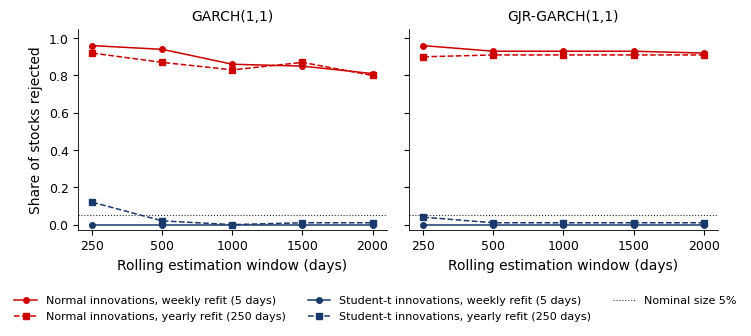

   saved ch8_bd_table3
Checking Rscript and esback before the forecast grid...


Forecast grid: 550 tasks; joblib reports completed batches.


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=-1)]: Done   1 tasks      | elapsed:    9.5s


[Parallel(n_jobs=-1)]: Done   4 tasks      | elapsed:   13.4s


...

[Parallel(n_jobs=-1)]: Done 541 tasks      | elapsed: 48.9min


Forecast grid complete: 550 series. Starting ESR regressions in R.


[Parallel(n_jobs=-1)]: Done 550 out of 550 | elapsed: 49.7min finished


R ESR stage complete: 550 regression results.


ESR fits: 550 attempted, 550 valid, 0 failed; rejection shares use valid fits only.
Valid denominators by distribution, window and refit:
dist    w     refit
normal  250   5        11
              21       11
              62       11
              125      11
              250      11
        500   5        11
              21       11
              62       11
              125      11
              250      11
        1000  5        11
              21       11
              62       11
              125      11
              250      11
        1500  5        11
              21       11
              62       11
              125      11
              250      11
        2000  5        11
              21       11
              62       11
              125      11
              250      11
t       250   5        11
              21       11
              62       11
              125      11
              250      11
        500   5        11
              21       11
          

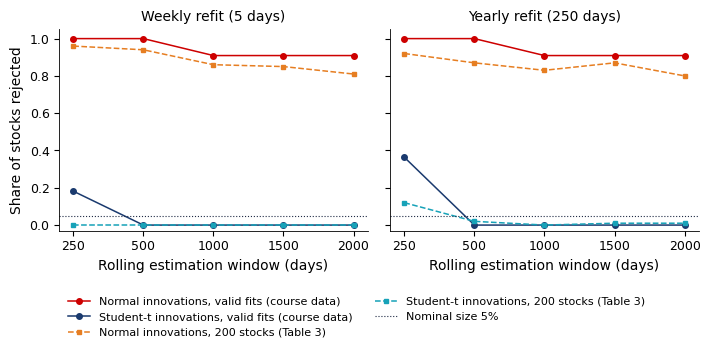

   saved ch8_bd_replication
{'T': 2432, 'n_stocks': 11, 'n_attempted': 550, 'n_valid': 550, 'failed_fits': [], 'share_n': {'250': {'5': 1.0, '21': 1.0, '62': 1.0, '125': 1.0, '250': 1.0}, '500': {'5': 1.0, '21': 1.0, '62': 1.0, '125': 1.0, '250': 1.0}, '1000': {'5': 0.9090909090909091, '21': 0.9090909090909091, '62': 0.8181818181818182, '125': 0.9090909090909091, '250': 0.9090909090909091}, '1500': {'5': 0.9090909090909091, '21': 0.9090909090909091, '62': 0.9090909090909091, '125': 0.9090909090909091, '250': 0.9090909090909091}, '2000': {'5': 0.9090909090909091, '21': 0.9090909090909091, '62': 0.9090909090909091, '125': 0.9090909090909091, '250': 0.9090909090909091}}, 'share_t': {'250': {'5': 0.18181818181818182, '21': 0.09090909090909091, '62': 0.2727272727272727, '125': 0.5454545454545454, '250': 0.36363636363636365}, '500': {'5': 0.0, '21': 0.0, '62': 0.0, '125': 0.09090909090909091, '250': 0.0}, '1000': {'5': 0.0, '21': 0.0, '62': 0.0, '125': 0.0, '250': 0.0}, '1500': {'5': 0.0, '2

In [ ]:
fig_bd_table3()
rows, share = bd_replication()
print(fig_bd_replication(rows, share))

![ch8_bd_table3](./ch8_bd_table3.png)

Output: `ch8_bd_table3.pdf`

![ch8_bd_replication](./ch8_bd_replication.png)

Output: `ch8_bd_replication.pdf`